In [11]:
import os

import pandas as pd
import numpy as np

import librosa
import librosa.display

import squarify
import matplotlib.pyplot as plt


In [12]:
df = pd.read_csv("../datasets/all_respiratory_metadata.csv")
df.head(3)

,start,end,crackle,wheeze,patient_number,recording_index,chest_location,acquisition_mode,recording_equipment,source_file
0,0.036,0.579,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron
1,0.579,2.450,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron
2,2.450,3.893,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron


In [4]:
df_diagnosis = pd.read_csv("../datasets/patient_diagnosis.csv", names=['patient_number','diagnosis'])
df_diagnosis.columns



Index(['patient_number', 'diagnosis'], dtype='object')

In [5]:
df_diagnosis.head(3)

,patient_number,diagnosis
0,101,URTI
1,102,Healthy
2,103,Asthma


In [6]:
df = pd.merge(df, df_diagnosis, on="patient_number")
df.head(3)

,start,end,crackle,wheeze,patient_number,recording_index,chest_location,acquisition_mode,recording_equipment,source_file,diagnosis
0,0.036,0.579,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron,URTI
1,0.579,2.450,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron,URTI
2,2.450,3.893,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron,URTI


In [7]:
df["recording_equipment"].unique()


array(['Meditron', 'LittC2SE', 'Litt3200', 'AKGC417L'], dtype=object)

In [8]:
df = df.drop(['recording_index'], axis=1)

In [9]:
df.head(3)

,start,end,crackle,wheeze,patient_number,chest_location,acquisition_mode,recording_equipment,source_file,diagnosis
0,0.036,0.579,0,0,101,Al,sc,Meditron,101_1b1_Al_sc_Meditron,URTI
1,0.579,2.450,0,0,101,Al,sc,Meditron,101_1b1_Al_sc_Meditron,URTI
2,2.450,3.893,0,0,101,Al,sc,Meditron,101_1b1_Al_sc_Meditron,URTI


In [14]:
df.insert(2, "duration", df["end"] - df["start"])
df.head(3)

,start,end,duration,crackle,wheeze,patient_number,recording_index,chest_location,acquisition_mode,recording_equipment,source_file
0,0.036,0.579,0.543,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron
1,0.579,2.450,1.871,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron
2,2.450,3.893,1.443,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron


### Distribution of Audio Duration at Breathe Cycle Level

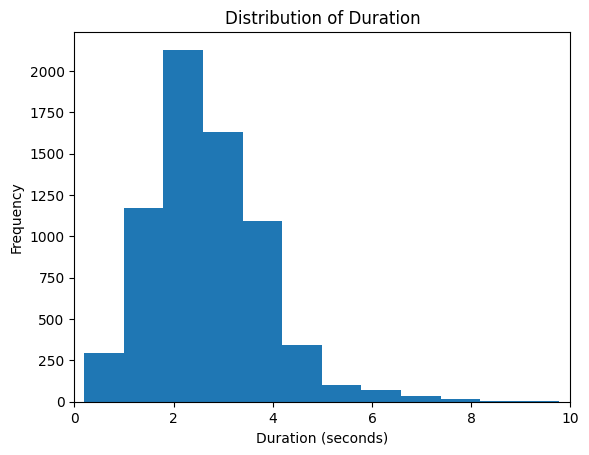

In [15]:

plt.hist(df["duration"], bins=20)
plt.xlabel("Duration (seconds)")
plt.ylabel("Frequency")
plt.title("Distribution of Duration")
plt.xlim(0, 10)
plt.show()


### Count of each Category on Bar Chart:

In [17]:
def catogory(row):
    if row["crackle"] == 1 and row["wheeze"] == 1:
        return "crackle & wheeze"
    elif row["crackle"] == 1:
        return "Only Crackle"
    elif row["wheeze"] == 1:
        return "Only Wheeze"
    else:
        return "Healthy"

df["category"] = df.apply(catogory, axis=1)

df["category"].value_counts()


category
Healthy             3642
Only Crackle        1864
Only Wheeze          886
crackle & wheeze     506
Name: count, dtype: int64

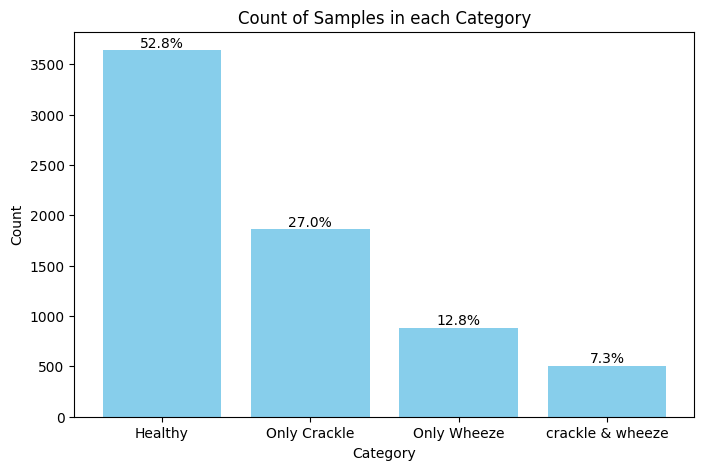

In [21]:
# Count each category
counts = df["category"].value_counts()
total = counts.sum()
percentages = counts / total * 100

# Plot
plt.figure(figsize=(8,5))
bars = plt.bar(counts.index, counts.values, color="skyblue")

# Add percentages on top
for bar, perc in zip(bars, percentages):
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, height + 1, f'{perc:.1f}%', ha='center', va='bottom')

plt.xlabel("Category")
plt.ylabel("Count")
plt.title("Count of Samples in each Category")
plt.show()


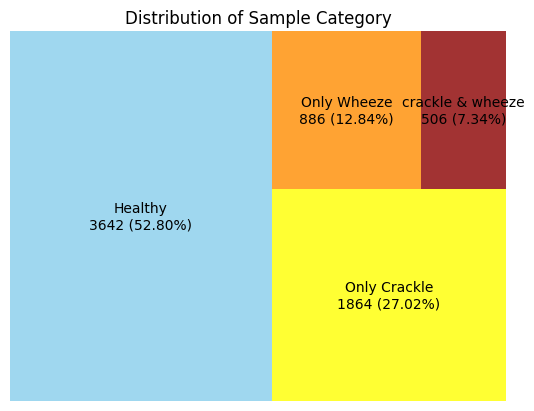

In [26]:


counts = df['category'].value_counts()

# Labels with percentages
total = counts.sum()
labels = [f"{cat}\n{count} ({count/total*100:.2f}%)" for cat, count in zip(counts.index, counts.values)]


squarify.plot(sizes=counts.values, label=labels, alpha=0.8, color=["skyblue","yellow","darkorange","darkred"])
plt.axis('off')
plt.title("Distribution of Sample Category")
plt.show()


In [28]:
df.to_csv('../datasets/metadata_df.csv', index=False)

### Visualization of a Respiratory Cycle

In [29]:
# Load an audio sample: I chose `105_1b1_Tc_sc_Meditron.wav`

file_path = "../datasets/audios/105_1b1_Tc_sc_Meditron.wav"
y, sr = librosa.load(file_path, sr=None)  # y = waveform, sr = sampling rate


In [32]:
# Compute Mel-spectrogram

mel_spectrogram = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)

# Convert to log scale (dB)
log_mel_spectrogram = librosa.power_to_db(mel_spectrogram, ref=np.max)

print(mel_spectrogram.shape)  # (n_mels, n_frames)


(128, 1723)


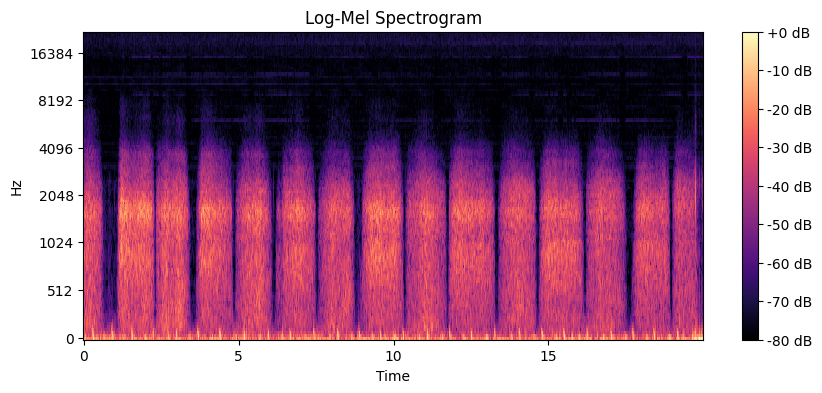

In [35]:
plt.figure(figsize=(10, 4))
librosa.display.specshow(log_mel_spectrogram, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title('Log-Mel Spectrogram')
plt.show()

plt.close()


In [36]:
df_healthy = df[df['category']=='Healthy']


In [37]:
df_healthy.head(3)

,start,end,duration,crackle,wheeze,patient_number,recording_index,chest_location,acquisition_mode,recording_equipment,source_file,category
0,0.036,0.579,0.543,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron,Healthy
1,0.579,2.450,1.871,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron,Healthy
2,2.450,3.893,1.443,0,0,101,1b1,Al,sc,Meditron,101_1b1_Al_sc_Meditron,Healthy


In [38]:
AUDIO_DIR = "../datasets/audios"
output_dir = "../datasets/images/mel_spectrograms_healthy"
os.makedirs(output_dir, exist_ok=True)

In [62]:
counter = 0
for idx, row in df_healthy.iterrows():
    filename = row["source_file"]
    file_path = os.path.join(AUDIO_DIR, filename + ".wav")

    start_time = row["start"]
    end_time = row["end"]

    try:
        # Load full audio
        y, sr = librosa.load(file_path, sr=None)

        # Convert time → samples
        start_sample = int(start_time * sr)
        end_sample = int(end_time * sr)

        # Extract segment
        y_segment = y[start_sample:end_sample]

        # Skip empty segments
        if len(y_segment) == 0:
            continue

        # ===== Mel Spectrogram =====
        mel = librosa.feature.melspectrogram(
            y=y_segment,
            sr=sr,
            n_mels=128,
            fmax=8000
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        # ===== HIGH-QUALITY PLOTTING =====
        plt.figure(figsize=(12, 6))  # larger figure
        librosa.display.specshow(
            log_mel,
            sr=sr,
            x_axis="time",
            y_axis="mel"
        )

        # Optional: remove axes for ML
        plt.axis("off")

        plt.tight_layout()

        # Save with high DPI
        save_name = f"healthy_{filename}_{idx}.png"
        save_path = os.path.join(output_dir, save_name)
        print(f"\rProcessing file {counter}/{len(df_healthy["source_file"])} ::: {save_name}", end="", flush=True)
        counter += 1
        
        plt.savefig(
            save_path,
            dpi=300, 
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

    except Exception as e:
        print(f"Error processing {filename}: {e}")


Processing file 39/3642 ::: healthy_104_1b1_Al_sc_Litt3200_43.png

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Processing file 3641/3642 ::: healthy_226_1b1_Pl_sc_LittC2SE_6897.png

In [ ]:
AUDIO_DIR = "../datasets/audios"
output_dir = "../datasets/images/mel_spectrograms_healthy_WholeRecord"
os.makedirs(output_dir, exist_ok=True)

In [56]:
df_healthy_unique = df_healthy["source_file"].unique()

for counter, filename in enumerate(df_healthy_unique, start=1):
    file_path = os.path.join(AUDIO_DIR, filename + ".wav")

    try:
        # Load full audio
        y, sr = librosa.load(file_path, sr=None)

        # Mel spectrogram
        mel = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_mels=128,
            fmax=8000
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        # High-quality plotting
        plt.figure(figsize=(12, 6))
        librosa.display.specshow(
            log_mel,
            sr=sr,
            x_axis="time",
            y_axis="mel"
        )

        plt.axis("off")
        plt.tight_layout()

        save_name = f"healthy_{filename}.png"
        save_path = os.path.join(output_dir, save_name)

        print(f"\rProcessing file {counter}/{len(df_healthy_unique)}", end="", flush=True)

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

    except Exception as e:
        print(f"\nError processing {filename}: {e}")


Processing file 5/714

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Processing file 714/714

In [63]:
df_crackle = df[df['category']=='Only Crackle']
df_wheeze = df[df['category']=='Only Wheeze']
df_crackle_wheeze = df[df['category']=='crackle & wheeze']

In [ ]:
output_dir = "../datasets/images/mel_spectrograms_crackle"
os.makedirs(output_dir, exist_ok=True)

In [64]:
counter = 1
for idx, row in df_crackle.iterrows():
    filename = row["source_file"]
    file_path = os.path.join(AUDIO_DIR, filename + ".wav")

    start_time = row["start"]
    end_time = row["end"]

    try:
        # Load full audio
        y, sr = librosa.load(file_path, sr=None)

        # Convert time → samples
        start_sample = int(start_time * sr)
        end_sample = int(end_time * sr)

        # Extract segment
        y_segment = y[start_sample:end_sample]

        # Skip empty segments
        if len(y_segment) == 0:
            continue

        # ===== Mel Spectrogram =====
        mel = librosa.feature.melspectrogram(
            y=y_segment,
            sr=sr,
            n_mels=128,
            fmax=8000
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        # ===== HIGH-QUALITY PLOTTING =====
        plt.figure(figsize=(12, 6))  # larger figure
        librosa.display.specshow(
            log_mel,
            sr=sr,
            x_axis="time",
            y_axis="mel"
        )

        # Optional: remove axes for ML
        plt.axis("off")

        plt.tight_layout()

        # Save with high DPI
        save_name = f"crackle_{filename}_{idx}.png"
        save_path = os.path.join(output_dir, save_name)
        print(f"\rProcessing file {counter}/{len(df_crackle["source_file"])} ::: {save_name}", end="", flush=True)
        counter += 1
        
        plt.savefig(
            save_path,
            dpi=300,                 # 🔥 key improvement
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

    except Exception as e:
        print(f"Error processing {filename}: {e}")


Processing file 1/1864 ::: crackle_104_1b1_Ll_sc_Litt3200_66.png

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Processing file 153/1864 ::: crackle_110_1b1_Pr_sc_Meditron_423.png

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\core\spectrum.py:266: UserWarning: n_fft=2048 is too large for input signal of length=1848
  warnings.warn(


Processing file 1864/1864 ::: crackle_226_1b1_Pl_sc_LittC2SE_6896.png

In [ ]:
output_dir = "../datasets/images/mel_spectrograms_crackle_WholeRecord"
os.makedirs(output_dir, exist_ok=True)

In [65]:
df_crackle_unique = df_crackle["source_file"].unique()

for counter, filename in enumerate(df_crackle_unique, start=1):
    file_path = os.path.join(AUDIO_DIR, filename + ".wav")

    try:
        # Load full audio
        y, sr = librosa.load(file_path, sr=None)

        # Mel spectrogram
        mel = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_mels=128,
            fmax=8000
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        # High-quality plotting
        plt.figure(figsize=(12, 6))
        librosa.display.specshow(
            log_mel,
            sr=sr,
            x_axis="time",
            y_axis="mel"
        )

        plt.axis("off")
        plt.tight_layout()

        save_name = f"crackle_{filename}.png"
        save_path = os.path.join(output_dir, save_name)

        print(f"\rProcessing file {counter}/{len(df_crackle_unique)}", end="", flush=True)

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

    except Exception as e:
        print(f"\nError processing {filename}: {e}")


Processing file 1/432

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Processing file 432/432

In [39]:
output_dir = "../datasets/images/mel_spectrograms_wheeze"
os.makedirs(output_dir, exist_ok=True)

In [66]:
counter = 1
for idx, row in df_wheeze.iterrows():
    filename = row["source_file"]
    file_path = os.path.join(AUDIO_DIR, filename + ".wav")

    start_time = row["start"]
    end_time = row["end"]

    try:
        # Load full audio
        y, sr = librosa.load(file_path, sr=None)

        # Convert time → samples
        start_sample = int(start_time * sr)
        end_sample = int(end_time * sr)

        # Extract segment
        y_segment = y[start_sample:end_sample]

        # Skip empty segments
        if len(y_segment) == 0:
            continue

        # ===== Mel Spectrogram =====
        mel = librosa.feature.melspectrogram(
            y=y_segment,
            sr=sr,
            n_mels=128,
            fmax=8000
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        # ===== HIGH-QUALITY PLOTTING =====
        plt.figure(figsize=(12, 6))  # larger figure
        librosa.display.specshow(
            log_mel,
            sr=sr,
            x_axis="time",
            y_axis="mel"
        )

        # Optional: remove axes for ML
        plt.axis("off")

        plt.tight_layout()

        # Save with high DPI
        save_name = f"wheeze_{filename}_{idx}.png"
        save_path = os.path.join(output_dir, save_name)
        print(f"\rProcessing file {counter}/{len(df_wheeze["source_file"])} ::: {save_name}", end="", flush=True)
        counter += 1
        
        plt.savefig(
            save_path,
            dpi=300,                 # 🔥 key improvement
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

    except Exception as e:
        print(f"Error processing {filename}: {e}")


Processing file 6/886 ::: wheeze_104_1b1_Ar_sc_Litt3200_49.png

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Processing file 886/886 ::: wheeze_223_1b1_Pr_sc_Meditron_6838.png

In [ ]:
output_dir = "../datasets/images/mel_spectrograms_wheeze_WholeRecord"
os.makedirs(output_dir, exist_ok=True)

In [67]:
df_wheeze_unique = df_wheeze["source_file"].unique()

for counter, filename in enumerate(df_wheeze_unique, start=1):
    file_path = os.path.join(AUDIO_DIR, filename + ".wav")

    try:
        # Load full audio
        y, sr = librosa.load(file_path, sr=None)

        # Mel spectrogram
        mel = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_mels=128,
            fmax=8000
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        # High-quality plotting
        plt.figure(figsize=(12, 6))
        librosa.display.specshow(
            log_mel,
            sr=sr,
            x_axis="time",
            y_axis="mel"
        )

        plt.axis("off")
        plt.tight_layout()

        save_name = f"crackle_{filename}.png"
        save_path = os.path.join(output_dir, save_name)

        print(f"\rProcessing file {counter}/{len(df_wheeze_unique)}", end="", flush=True)

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

    except Exception as e:
        print(f"\nError processing {filename}: {e}")


Processing file 2/255

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Processing file 255/255

In [ ]:
output_dir = "../datasets/images/mel_spectrograms_crackle_wheeze"
os.makedirs(output_dir, exist_ok=True)

In [68]:
counter = 1
for idx, row in df_crackle_wheeze.iterrows():
    filename = row["source_file"]
    file_path = os.path.join(AUDIO_DIR, filename + ".wav")

    start_time = row["start"]
    end_time = row["end"]

    try:
        # Load full audio
        y, sr = librosa.load(file_path, sr=None)

        # Convert time → samples
        start_sample = int(start_time * sr)
        end_sample = int(end_time * sr)

        # Extract segment
        y_segment = y[start_sample:end_sample]

        # Skip empty segments
        if len(y_segment) == 0:
            continue

        # ===== Mel Spectrogram =====
        mel = librosa.feature.melspectrogram(
            y=y_segment,
            sr=sr,
            n_mels=128,
            fmax=8000
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        # ===== HIGH-QUALITY PLOTTING =====
        plt.figure(figsize=(12, 6))  # larger figure
        librosa.display.specshow(
            log_mel,
            sr=sr,
            x_axis="time",
            y_axis="mel"
        )

        # Optional: remove axes for ML
        plt.axis("off")

        plt.tight_layout()

        # Save with high DPI
        save_name = f"crackle_wheeze_{filename}_{idx}.png"
        save_path = os.path.join(output_dir, save_name)
        print(f"\rProcessing file {counter}/{len(df_crackle_wheeze["source_file"])} ::: {save_name}", end="", flush=True)
        counter += 1
        
        plt.savefig(
            save_path,
            dpi=300,                 # 🔥 key improvement
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

    except Exception as e:
        print(f"Error processing {filename}: {e}")


Processing file 34/506 ::: crackle_wheeze_110_1p1_Al_sc_Meditron_439.png

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Processing file 506/506 ::: crackle_wheeze_221_2b3_Pr_mc_LittC2SE_6732.png

In [ ]:
output_dir = "../datasets/images/mel_spectrograms_crackle_wheeze_WholeRecord"
os.makedirs(output_dir, exist_ok=True)

In [69]:
df_crackle_wheeze_unique = df_crackle_wheeze["source_file"].unique()

for counter, filename in enumerate(df_crackle_wheeze_unique, start=1):
    file_path = os.path.join(AUDIO_DIR, filename + ".wav")

    try:
        # Load full audio
        y, sr = librosa.load(file_path, sr=None)

        # Mel spectrogram
        mel = librosa.feature.melspectrogram(
            y=y,
            sr=sr,
            n_mels=128,
            fmax=8000
        )

        log_mel = librosa.power_to_db(mel, ref=np.max)

        # High-quality plotting
        plt.figure(figsize=(12, 6))
        librosa.display.specshow(
            log_mel,
            sr=sr,
            x_axis="time",
            y_axis="mel"
        )

        plt.axis("off")
        plt.tight_layout()

        save_name = f"crackle_wheeze_{filename}.png"
        save_path = os.path.join(output_dir, save_name)

        print(f"\rProcessing file {counter}/{len(df_crackle_wheeze_unique)}", end="", flush=True)

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight",
            pad_inches=0
        )
        plt.close()

    except Exception as e:
        print(f"\nError processing {filename}: {e}")


Processing file 12/171

D:\.JKU CS courses\Master Thesis\.venv\Lib\site-packages\librosa\feature\spectral.py:2148: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


Processing file 171/171

### Next Step: 
Preprocessing and feature extraction step is done. <br>
To build a random forest model open `02.random_forest_model.ipynb`